saved the figure
saved the animation


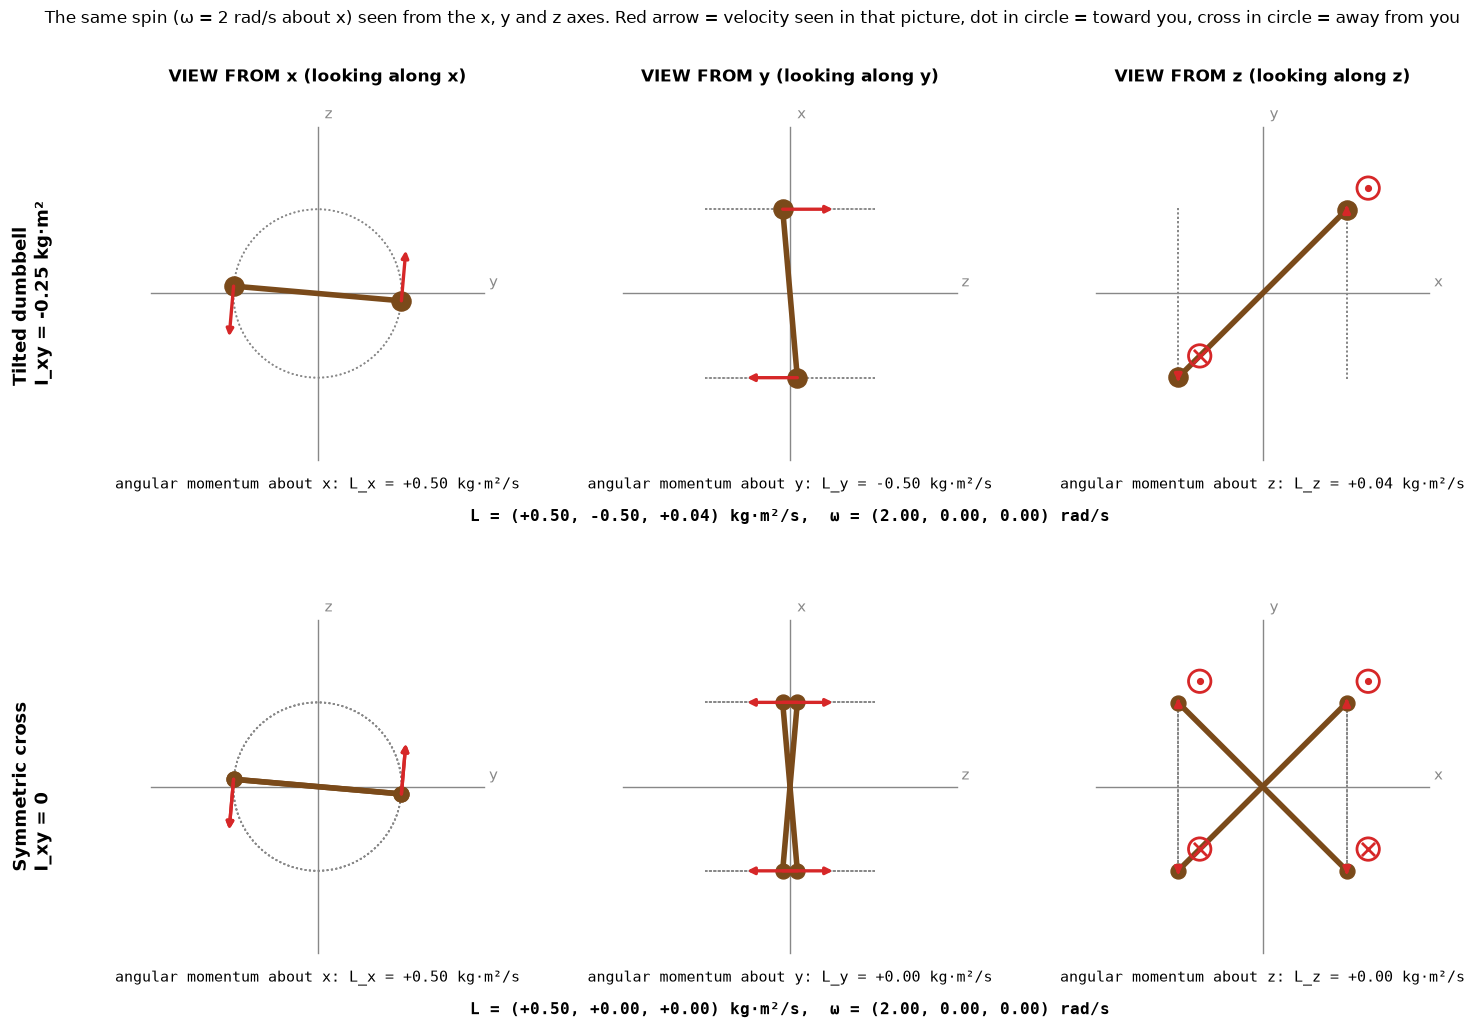

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.animation import FuncAnimation, PillowWriter  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: two mass layouts, same spin
#   What we have: omega = 2 rad/s about the lab x axis (the spin is the same in both rows)
#     row 1: dumbbell, two 1 kg masses at +-(0.354, 0.354, 0) m  (a tilted line, 45 degrees in the xy plane)
#     row 2: cross, four 0.5 kg masses at (+-0.354, +-0.354, 0) m (same total mass, same I_xx, symmetric)
#   What we want: see I_xy as a motion seen from the x, y and z axes
#   Why: L = sum m r x v,  v = omega x r = (0, -2 z, 2 y),  L_y = sum m (z v_x - x v_z) = -2 sum m x y = 2 I_xy
# ---------------------------------------------------------------
OMEGA = 2.0
OMEGA_VEC = np.array([OMEGA, 0.0, 0.0])
Q = 0.5 * np.sin(np.deg2rad(45.0))  # 0.354 m
LAYOUTS = [
    dict(name="Tilted dumbbell", sub="I_xy = -0.25 kg·m²",
         pos=np.array([[Q, Q, 0.0], [-Q, -Q, 0.0]]), mass=np.array([1.0, 1.0]), links=[(0, 1)]),
    dict(name="Symmetric cross", sub="I_xy = 0",
         pos=np.array([[Q, Q, 0.0], [-Q, -Q, 0.0], [Q, -Q, 0.0], [-Q, Q, 0.0]]),
         mass=np.array([0.5, 0.5, 0.5, 0.5]), links=[(0, 1), (2, 3)]),
]
N_FRAMES, FPS = 72, 20
BROWN, RED, GRAY = "#7a4a1a", "#d62728", "#888888"

# the view from each axis: (horizontal axis index, vertical axis index, index of the axis you look along)
# cyclic order keeps counterclockwise = positive rotation about the viewing axis
VIEWS = [("x", 1, 2, 0), ("y", 2, 0, 1), ("z", 0, 1, 2)]
NAMES = "xyz"


def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


# ---------------------------------------------------------------
# STEP 3: draw one instant
#   What we have: theta = OMEGA t, positions r_i = Rx(theta) r_i0, velocities v_i = omega x r_i
#   What we want: 3 flat pictures per layout (looking along x, y, z), red arrows = velocity seen in that picture
#   Why: a spin looks like a turn about the axis you look along when the masses go around it;
#        two masses on opposite sides moving oppositely look like a see-saw about that axis (= angular momentum there)
#   marker: circle with dot = coming toward you, circle with cross = going away (motion along your line of sight)
# ---------------------------------------------------------------
def draw(theta, axes, texts):
    for row, lay in enumerate(LAYOUTS):
        r = (Rx(theta) @ lay["pos"].T).T
        v = np.cross(OMEGA_VEC, r)
        m = lay["mass"]
        L = (m[:, None] * np.cross(r, v)).sum(axis=0)
        phi = np.linspace(0, 2 * np.pi, 100)
        for col, (vn, hi, vi, li) in enumerate(VIEWS):
            ax = axes[row][col]
            ax.cla()
            ax.set_xlim(-0.75, 0.75)
            ax.set_ylim(-0.75, 0.75)
            ax.set_aspect("equal")
            ax.axis("off")
            ax.plot([-0.7, 0.7], [0, 0], color=GRAY, lw=1.0)
            ax.plot([0, 0], [-0.7, 0.7], color=GRAY, lw=1.0)
            ax.text(0.72, 0.03, NAMES[hi], color=GRAY, fontsize=11, ha="left")
            ax.text(0.03, 0.72, NAMES[vi], color=GRAY, fontsize=11, va="bottom")
            for p0 in lay["pos"]:
                pts = np.array([Rx(f) @ p0 for f in phi])
                ax.plot(pts[:, hi], pts[:, vi], color=GRAY, ls=":", lw=1.2)
            for i, j in lay["links"]:
                ax.plot([r[i, hi], r[j, hi]], [r[i, vi], r[j, vi]], color=BROWN, lw=4, zorder=3)
            for k in range(len(m)):
                ax.scatter(r[k, hi], r[k, vi], s=150 * m[k] + 40, color=BROWN, zorder=4)
                vin = np.array([v[k, hi], v[k, vi]])
                if np.linalg.norm(vin) > 0.05:
                    ax.annotate("", xy=(r[k, hi] + 0.3 * vin[0], r[k, vi] + 0.3 * vin[1]), xytext=(r[k, hi], r[k, vi]),
                                arrowprops=dict(arrowstyle="-|>", color=RED, lw=2.4, shrinkA=0, shrinkB=0), zorder=5)
                vout = v[k, li]
                if abs(vout) > 0.1:
                    mx, my = r[k, hi] + 0.09, r[k, vi] + 0.09
                    ax.scatter(mx, my, s=260, facecolors="none", edgecolors=RED, linewidths=2.0, zorder=6)
                    ax.scatter(mx, my, s=40 if vout > 0 else 90, color=RED, marker="." if vout > 0 else "x",
                               linewidths=2.0, zorder=7)
            if row == 0:
                ax.set_title(f"VIEW FROM {vn} (looking along {vn})", fontsize=12.5, fontweight="bold", y=1.07)
            texts[row][col].set_text(f"angular momentum about {vn}: L_{vn} = {round(L[li], 2) + 0.0:+.2f} kg·m²/s")
        texts[row][3].set_text(f"L = ({round(L[0], 2) + 0.0:+.2f}, {round(L[1], 2) + 0.0:+.2f}, {round(L[2], 2) + 0.0:+.2f}) kg·m²/s,  ω = (2.00, 0.00, 0.00) rad/s")


fig = plt.figure(figsize=(15, 10.5))
gs = fig.add_gridspec(2, 3, left=0.06, right=0.99, top=0.88, bottom=0.07, hspace=0.38, wspace=0.05)
axes = [[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(2)]
texts = [[None] * 4 for _ in range(2)]
for r in range(2):
    for c in range(3):
        pos = axes[r][c].get_position()
        texts[r][c] = fig.text((pos.x0 + pos.x1) / 2, pos.y0 - 0.005, "", ha="center", va="top", fontsize=10.5, family="monospace")
    pos0, pos2 = axes[r][0].get_position(), axes[r][2].get_position()
    texts[r][3] = fig.text((pos0.x0 + pos2.x1) / 2, pos0.y0 - 0.035, "", ha="center", va="top", fontsize=11.5,
                           family="monospace", fontweight="bold")
    fig.text(0.005, (pos0.y0 + pos0.y1) / 2, f"{LAYOUTS[r]['name']}\n{LAYOUTS[r]['sub']}", rotation=90, va="center",
             ha="left", fontsize=13, fontweight="bold")
fig.suptitle("The same spin (ω = 2 rad/s about x) seen from the x, y and z axes. Red arrow = velocity seen in that picture, "
             "dot in circle = toward you, cross in circle = away from you", fontsize=12.5)

# ---------------------------------------------------------------
# STEP 4: save a snapshot (theta = 0) and a GIF of one full turn
#   Why: the snapshot shows the see-saw at its strongest, the GIF shows it come and go as the masses go around
# ---------------------------------------------------------------
draw(0.0, axes, texts)
png_path = os.path.join(RESULT_DIR, f"ixy_views_{TIMESTAMP}.png")
plt.savefig(png_path, dpi=120)
print("saved the figure")


def update(i):
    draw(2 * np.pi * i / N_FRAMES, axes, texts)
    return []


anim = FuncAnimation(fig, update, frames=N_FRAMES, interval=1000 / FPS, blit=False)
gif_path = os.path.join(RESULT_DIR, f"ixy_views_{TIMESTAMP}.gif")
anim.save(gif_path, writer=PillowWriter(fps=FPS), dpi=70)
print("saved the animation")
plt.show()